In [1]:
# import library

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sqlalchemy import create_engine, text

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [2]:
import pandas as pd

df = pd.read_csv(r"C:\CHURNIQ\SQL\psql telco_customers_data.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (7043, 21)


,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,onlinebackup,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Create the binary churn target

In [3]:

# Encode the churn target
# Purpose: Convert the churn label into a numeric target for machine learning.
df["churn"] = df["churn"].astype("string").str.strip()

churn_mapping = {
    "Yes": 1,
    "No": 0
}

unexpected_values = (
    set(df["churn"].dropna().unique())
    - set(churn_mapping.keys())
)

if unexpected_values:
    raise ValueError(
        f"Unexpected Churn values: {unexpected_values}"
    )

df["churn_target"] = df["churn"].map(churn_mapping)

print("churn target counts:")
display(df["churn_target"].value_counts(dropna=False))

print("\nchurn target percentages:")
display(
    df["churn_target"]
      .value_counts(normalize=True, dropna=False)
      .mul(100)
      .round(2)
)


churn target counts:


churn_target
0    5174
1    1869
Name: count, dtype: int64


churn target percentages:


churn_target
0    73.46
1    26.54
Name: proportion, dtype: float64

### Engineer tenure features

In [7]:

# Tenure-based features
# Purpose: Create customer lifecycle indicators from tenure.

df["tenure_months"] = pd.to_numeric(
    df["tenure"], errors="coerce"
)

df["customer_age_group"] = pd.cut(
    df["tenure_months"],
    bins=[-1, 6, 12, 24, 48, float("inf")],
    labels=[
        "0-6 months",
        "7-12 months",
        "13-24 months",
        "25-48 months",
        "49+ months"
    ],
    include_lowest=True
)

df["is_new_customer"] = (
    df["tenure_months"].between(0, 6)
).astype("int8")

df["is_long_term_customer"] = (
    df["tenure_months"] >= 24
).astype("int8")

display(
    df[
        [
            "tenure",
            "tenure_months",
            "customer_age_group",
            "is_new_customer",           # for 0-6 months    
            "is_long_term_customer"      # for 24 months
        ]
    ].head(10)
)


,tenure,tenure_months,customer_age_group,is_new_customer,is_long_term_customer
0,1,1,0-6 months,1,0
1,34,34,25-48 months,0,1
2,2,2,0-6 months,1,0
3,45,45,25-48 months,0,1
4,2,2,0-6 months,1,0
5,8,8,7-12 months,0,0
6,22,22,13-24 months,0,0
7,10,10,7-12 months,0,0
8,28,28,25-48 months,0,1
9,62,62,49+ months,0,1


### Engineer billing-based features

In [18]:

# Billing feature engineering
# Purpose: Derive additional billing indicators from monthly and total charges.
if {"monthlycharges", "totalcharges"}.issubset(df.columns):

    df["monthlycharges"] = pd.to_numeric(
        df["monthlycharges"], errors="coerce"
    
    )

    df["totalcharges"] = pd.to_numeric(
        df["totalcharges"], errors="coerce"
    )

    valid_tenure = df["tenure_months"].where(
        df["tenure_months"] > 0
    )

    df["avg_historical_monthly_charge"] = (
        df["totalcharges"] / valid_tenure
    )

    df["charge_difference"] = (
        df["monthlycharges"]
        - df["avg_historical_monthly_charge"]
    )

    df["charge_difference_pct"] = (
        df["charge_difference"]
        / df["avg_historical_monthly_charge"].where(
            df["avg_historical_monthly_charge"] > 0
        )
    )

    display(
        df[
            [
                "tenure_months",
                "monthlycharges",
                "totalcharges",
                "avg_historical_monthly_charge",
                "charge_difference",
                "charge_difference_pct"
            ]
        ]
    )

else:
    print("monthlycharges or totalcharges is unavailable.")


,tenure_months,monthlycharges,totalcharges,avg_historical_monthly_charge,charge_difference,charge_difference_pct
0,1,29.85,29.85,29.850000,0.000000,0.000000
1,34,56.95,1889.50,55.573529,1.376471,0.024768
2,2,53.85,108.15,54.075000,-0.225000,-0.004161
3,45,42.30,1840.75,40.905556,1.394444,0.034089
4,2,70.70,151.65,75.825000,-5.125000,-0.067590
...,...,...,...,...,...,...
7038,24,84.80,1990.50,82.937500,1.862500,0.022457
7039,72,103.20,7362.90,102.262500,0.937500,0.009168
7040,11,29.60,346.45,31.495455,-1.895455,-0.060182
7041,4,74.40,306.60,76.650000,-2.250000,-0.029354


### Engineer contract and service features

In [49]:

# Contract and service features
# Purpose: Represent contract commitment and the number of subscribed additional services.

if "contract" in df.columns:
    contract_clean = df["contract"].astype("string").str.strip()

    df["is_month_to_month"] = (
        contract_clean == "month-to-month"
    ).astype("int8")

    df["is_long_contract"] = (
        contract_clean.isin(["one year", "two year"])
    ).astype("int8")

service_columns = [
    "onlineSecurity",
    "onlineBackup",
    "deviceProtection",
    "techSupport",
    "streamingTV",
    "streamingMovies"
]

available_services = [
    col for col in service_columns
    if col in df.columns
]

if available_services:
    df["additional_services_count"] = (
        df[available_services]
        .eq("Yes")
        .sum(axis=1)
    )

preview_columns = [
    col for col in [
        "contract",
        "is_month_to_month",
        "is_long_contract",
        "additional_services_count"
    ]
    if col in df.columns
]

display(df[preview_columns].head(10))


,contract,is_month_to_month,is_long_contract
0,Month-to-month,0,0
1,One year,0,0
2,Month-to-month,0,0
3,One year,0,0
4,Month-to-month,0,0
5,Month-to-month,0,0
6,Month-to-month,0,0
7,Month-to-month,0,0
8,Month-to-month,0,0
9,One year,0,0


### Validate engineered features and missing values

In [50]:

# Data quality checks
# Purpose: Review data quality before preparing the initial model table.

print("Dataset shape:", df.shape)

print("\nMissing values:")
missing_summary = (
    df.isnull().sum()
      .loc[lambda s: s > 0]
      .sort_values(ascending=False)
)

if missing_summary.empty:
    print("No missing values detected.")
else:
    display(missing_summary)

print("\nDuplicate rows:", df.duplicated().sum())

print("\nEngineered features:")
engineered_columns = [
    "tenure_months",
    "customer_age_group",
    "is_new_customer",
    "is_long_term_customer",
    "avg_historical_monthly_charge",
    "charge_difference",
    "charge_difference_pct",
    "is_month_to_month",
    "is_long_contract",
    "additional_services_count"
]

print([
    col for col in engineered_columns
    if col in df.columns
])


Dataset shape: (7043, 31)

Missing values:


totalcharges                     11
avg_historical_monthly_charge    11
charge_difference                11
charge_difference_pct            11
dtype: int64


Duplicate rows: 0

Engineered features:
['tenure_months', 'customer_age_group', 'is_new_customer', 'is_long_term_customer', 'avg_historical_monthly_charge', 'charge_difference', 'charge_difference_pct', 'is_month_to_month', 'is_long_contract']


 ### Prepare the initial model feature table

In [51]:

# Create the initial model dataset
# Purpose: Create X (predictor features) and y (churn target) for the next notebook.

candidate_features = [
    "tenure_months",
    "is_new_customer",
    "is_long_term_customer",
    "MonthlyCharges",
    "TotalCharges",
    "avg_historical_monthly_charge",
    "charge_difference",
    "charge_difference_pct",
    "is_month_to_month",
    "is_long_contract",
    "additional_services_count",
    "Contract",
    "InternetService",
    "PaymentMethod",
    "PaperlessBilling",
    "TechSupport",
    "OnlineSecurity"
]

feature_columns = [
    col for col in candidate_features
    if col in df.columns
]

if "churn_target" not in df.columns:
    raise ValueError("Run Cell 25 before Cell 30.")

# Keep rows with a known target
model_data = df.loc[
    df["churn_target"].notna()
].copy()

X = model_data[feature_columns].copy()
y = model_data["churn_target"].astype("int8").copy()

print("Feature table shape:", X.shape)
print("Target shape:", y.shape)

print("\nSelected features:")
print(feature_columns)

print("\nCategorical features:")
print(X.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist())

print("\nTarget distribution:")
display(y.value_counts())

display(X.head())


Feature table shape: (7043, 8)
Target shape: (7043,)

Selected features:
['tenure_months', 'is_new_customer', 'is_long_term_customer', 'avg_historical_monthly_charge', 'charge_difference', 'charge_difference_pct', 'is_month_to_month', 'is_long_contract']

Categorical features:
[]

Target distribution:


churn_target
0    5174
1    1869
Name: count, dtype: int64

,tenure_months,is_new_customer,is_long_term_customer,avg_historical_monthly_charge,charge_difference,charge_difference_pct,is_month_to_month,is_long_contract
0,1,1,0,29.850000,0.000000,0.000000,0,0
1,34,0,1,55.573529,1.376471,0.024768,0,0
2,2,1,0,54.075000,-0.225000,-0.004161,0,0
3,45,0,1,40.905556,1.394444,0.034089,0,0
4,2,1,0,75.825000,-5.125000,-0.067590,0,0


### Verify X and y

In [52]:

# Cell 31: Verify the feature matrix and target

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts(dropna=False))

print("\nMissing values in X:", X.isna().sum().sum())
print("Missing values in y:", y.isna().sum())

# Check for identifier or target leakage
print("\nCustomerID included in X:", 
      any(col.lower() == "customerid".lower() for col in X.columns))

print("Churn included in X:",
      any(col.lower() == "churn" for col in X.columns))


Feature matrix shape: (7043, 8)
Target shape: (7043,)

Feature columns:
['tenure_months', 'is_new_customer', 'is_long_term_customer', 'avg_historical_monthly_charge', 'charge_difference', 'charge_difference_pct', 'is_month_to_month', 'is_long_contract']

Target distribution:
churn_target
0    5174
1    1869
Name: count, dtype: int64

Missing values in X: 33
Missing values in y: 0

CustomerID included in X: False
Churn included in X: False


In [53]:
# Cell 32: Identify missing values in X

missing_values = X.isna().sum()

missing_columns = missing_values[missing_values > 0]

print("Columns containing missing values:")
print(missing_columns)

print("\nTotal missing values:", X.isna().sum().sum())

print("\nRows containing missing values:")
display(X[X.isna().any(axis=1)].head(10))

Columns containing missing values:
avg_historical_monthly_charge    11
charge_difference                11
charge_difference_pct            11
dtype: int64

Total missing values: 33

Rows containing missing values:


,tenure_months,is_new_customer,is_long_term_customer,avg_historical_monthly_charge,charge_difference,charge_difference_pct,is_month_to_month,is_long_contract
488,0,1,0,NaN,NaN,NaN,0,0
753,0,1,0,NaN,NaN,NaN,0,0
936,0,1,0,NaN,NaN,NaN,0,0
1083,0,1,0,NaN,NaN,NaN,0,0
1344,0,1,0,NaN,NaN,NaN,0,0
3333,0,1,0,NaN,NaN,NaN,0,0
3828,0,1,0,NaN,NaN,NaN,0,0
4380,0,1,0,NaN,NaN,NaN,0,0
5218,0,1,0,NaN,NaN,NaN,0,0
6670,0,1,0,NaN,NaN,NaN,0,0


### Fix missing values in engineered features

In [54]:

#  Handle missing values in engineered features

# Customers with zero tenure have no historical billing history
new_customer_mask = X["tenure_months"] == 0

# Replace undefined historical billing features for new customers
billing_features = [
    "avg_historical_monthly_charge",
    "charge_difference",
    "charge_difference_pct"
]

X.loc[new_customer_mask, billing_features] = 0

print("Missing values after correction:", X.isna().sum().sum())

print("\nMissing values by column:")
print(X[billing_features].isna().sum())

print("\nNew customers checked:", new_customer_mask.sum())

print("\nSample of corrected rows:")
display(X.loc[new_customer_mask, billing_features].head())


Missing values after correction: 0

Missing values by column:
avg_historical_monthly_charge    0
charge_difference                0
charge_difference_pct            0
dtype: int64

New customers checked: 11

Sample of corrected rows:


,avg_historical_monthly_charge,charge_difference,charge_difference_pct
488,0.0,0.0,0.0
753,0.0,0.0,0.0
936,0.0,0.0,0.0
1083,0.0,0.0,0.0
1344,0.0,0.0,0.0


### verify feature matrix

In [55]:

#  Final data-quality check

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nTotal missing values in X:", X.isna().sum().sum())
print("Missing values in y:", y.isna().sum())

print("\nDuplicate rows in X:", X.duplicated().sum())
print("Target distribution:")
print(y.value_counts())


Feature matrix shape: (7043, 8)
Target shape: (7043,)

Total missing values in X: 0
Missing values in y: 0

Duplicate rows in X: 264
Target distribution:
churn_target
0    5174
1    1869
Name: count, dtype: int64


### Identify numerical and categorical features

In [56]:

#  Identify feature types
#We will use numerical scaling for numeric columns and one-hot encoding for categorical columns.

import numpy as np
import pandas as pd

numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool", "string"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)

print("\nNumber of numerical features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))


Numerical features: ['tenure_months', 'is_new_customer', 'is_long_term_customer', 'avg_historical_monthly_charge', 'charge_difference', 'charge_difference_pct', 'is_month_to_month', 'is_long_contract']

Categorical features: []

Number of numerical features: 8
Number of categorical features: 0


### Encode the target and split the data

In [57]:

# Encode target and split the data
#We'll convert the churn target into binary values (Yes = 1, No = 0) and create an 80/20 train/test split.

from sklearn.model_selection import train_test_split

# Convert y to a Series if needed
y = pd.Series(y, index=X.index, name="churn")

# Encode the target safely
if y.isna().any():
    raise ValueError("Target y contains missing values. Clean them first.")

if set(y.unique()).issubset({"Yes", "No"}):
    y = y.map({"No": 0, "Yes": 1})
elif set(y.unique()).issubset({0, 1, False, True}):
    y = y.astype(int)
else:
    raise ValueError(
        f"Unexpected target values: {y.unique()}"
    )

# Stratify to preserve the churn ratio
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining churn rate:")
print(y_train.mean().round(3))

print("\nTesting churn rate:")
print(y_test.mean().round(3))


Training features: (5634, 8)
Testing features: (1409, 8)

Training churn rate:
0.265

Testing churn rate:
0.265


### Build the preprocessing pipeline

In [58]:

#  Create the preprocessing pipeline

from sklearn.compose import ColumnTransformer                      #to apply the correct transformations to each column.
from sklearn.pipeline import Pipeline           
from sklearn.impute import SimpleImputer                           #to handle missing values
from sklearn.preprocessing import StandardScaler, OneHotEncoder    #to scale numerical value and to handle categorical features


numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully.")


Preprocessing pipeline created successfully.


### Train the first Logistic Regression model

In [59]:

# Train Logistic Regression

from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

print("Predictions generated:", len(y_pred))


Logistic Regression model trained successfully!
Predictions generated: 1409


### Evaluate model performance

MODEL PERFORMANCE
----------------------------------------
Accuracy:  0.7885
Precision: 0.6652
Recall:    0.4091
F1-score:  0.5066
ROC-AUC:   0.8127

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.81      0.93      0.87      1035
       Churn       0.67      0.41      0.51       374

    accuracy                           0.79      1409
   macro avg       0.74      0.67      0.69      1409
weighted avg       0.77      0.79      0.77      1409



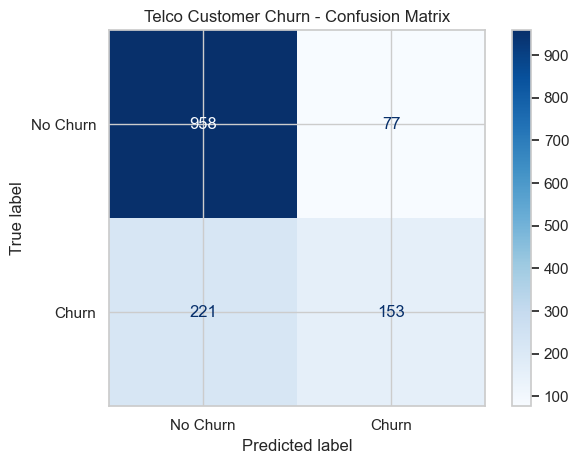

In [60]:
# Evaluate the model

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

print("MODEL PERFORMANCE")
print("-" * 40)

print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_proba):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Churn", "Churn"],
    zero_division=0
))

# Plot confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Churn", "Churn"],
    cmap="Blues"
)

plt.title("Telco Customer Churn - Confusion Matrix")
plt.tight_layout()
plt.savefig(
    "confusion_matrix_logistic_regression.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


### Run this diagnostic cell

In [61]:

#: Diagnose the baseline churn model

import pandas as pd
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

required_vars = [
    "X", "y", "X_train", "X_test",
    "y_train", "y_test", "model",
    "y_pred", "y_proba"
]

missing_vars = [
    var for var in required_vars
    if var not in globals()
]

if missing_vars:
    print("MISSING VARIABLES:", missing_vars)
    print("Run the earlier notebook cells first.")
else:
    print("=" * 55)
    print("1. DATA SHAPES")
    print("=" * 55)

    print("X:", X.shape)
    print("y:", y.shape)
    print("X_train:", X_train.shape)
    print("X_test:", X_test.shape)
    print("y_train:", y_train.shape)
    print("y_test:", y_test.shape)

    print("\n" + "=" * 55)
    print("2. TARGET DISTRIBUTION")
    print("=" * 55)

    print("Full dataset:")
    print(y.value_counts(dropna=False))
    print("\nTraining set:")
    print(y_train.value_counts(dropna=False))
    print("\nTesting set:")
    print(y_test.value_counts(dropna=False))

    print("\n" + "=" * 55)
    print("3. DATA QUALITY")
    print("=" * 55)

    print("Missing values in X:", X.isna().sum().sum())
    print("Missing values in y:", y.isna().sum())

    print("Duplicate feature column names:",
          X.columns.duplicated().sum())

    print("CustomerID in X:",
          any(c.lower() == "customerid" for c in X.columns))

    print("Churn in X:",
          any(c.lower() == "churn" for c in X.columns))

    print("\n" + "=" * 55)
    print("4. MODEL PERFORMANCE")
    print("=" * 55)

    print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
    print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
    print(f"Recall:    {recall_score(y_test, y_pred, zero_division=0):.4f}")
    print(f"F1-score:  {f1_score(y_test, y_pred, zero_division=0):.4f}")
    print(f"ROC-AUC:   {roc_auc_score(y_test, y_proba):.4f}")

    print("\nPrediction classes:")
    print(pd.Series(y_pred).value_counts().sort_index())

    print("\nChurn probability summary:")
    print(pd.Series(y_proba).describe().round(4))


1. DATA SHAPES
X: (7043, 8)
y: (7043,)
X_train: (5634, 8)
X_test: (1409, 8)
y_train: (5634,)
y_test: (1409,)

2. TARGET DISTRIBUTION
Full dataset:
churn
0    5174
1    1869
Name: count, dtype: int64

Training set:
churn
0    4139
1    1495
Name: count, dtype: int64

Testing set:
churn
0    1035
1     374
Name: count, dtype: int64

3. DATA QUALITY
Missing values in X: 0
Missing values in y: 0
Duplicate feature column names: 0
CustomerID in X: False
Churn in X: False

4. MODEL PERFORMANCE
Accuracy:  0.7885
Precision: 0.6652
Recall:    0.4091
F1-score:  0.5066
ROC-AUC:   0.8127

Prediction classes:
0    1179
1     230
Name: count, dtype: int64

Churn probability summary:
count    1409.0000
mean        0.2621
std         0.2206
min         0.0062
25%         0.0758
50%         0.1968
75%         0.4189
max         0.8697
dtype: float64


### Import libraries and verify existing variables

In [62]:

#  Import libraries and validate the existing split

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)

required_vars = ["X_train", "X_test", "y_train", "y_test",
                 "preprocessor"]

missing = [name for name in required_vars if name not in globals()]

if missing:
    raise NameError(
        f"Missing variables: {missing}. Run the earlier cells first."
    )

assert len(X_train) == len(y_train), "Training rows do not match target."
assert len(X_test) == len(y_test), "Testing rows do not match target."

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)
print("Training and testing data are ready.")


Training set: (5634, 8)
Testing set: (1409, 8)
Training and testing data are ready.


### Train both models

In [63]:

# Create and train both classification models

lr_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

rf_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train Logistic Regression
lr_model.fit(X_train, y_train)

# Train Random Forest
rf_model.fit(X_train, y_train)

print("Logistic Regression trained successfully.")
print("Random Forest trained successfully.")


Logistic Regression trained successfully.
Random Forest trained successfully.


### Compare evaluation metrics

In [64]:

# Evaluate and compare the models

models = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_model
}

results = []
predictions = {}
probabilities = {}

for name, fitted_model in models.items():
    pred = fitted_model.predict(X_test)
    proba = fitted_model.predict_proba(X_test)[:, 1]

    predictions[name] = pred
    probabilities[name] = proba

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(
            y_test, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, proba)
    })

comparison_df = pd.DataFrame(results).set_index("Model")

print("MODEL COMPARISON")
display(comparison_df.round(4))


MODEL COMPARISON


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.7885,0.6652,0.4091,0.5066,0.8127
Random Forest,0.7566,0.5463,0.4893,0.5162,0.7927


### Plot confusion matrices

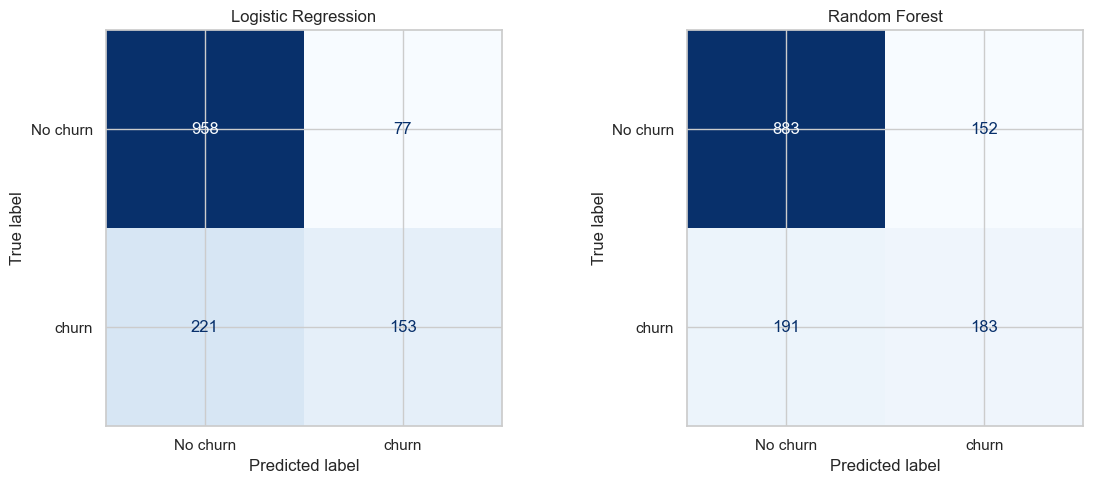

In [65]:

# : Compare confusion matrices

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, name in zip(axes, models.keys()):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions[name],
        labels=[0, 1],
        display_labels=["No churn", "churn"],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()
plt.savefig(
    "churn_model_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


### Print detailed classification reports

In [66]:

#  Detailed classification reports

for name in models:
    print("\n" + "=" * 60)
    print(name.upper())
    print("=" * 60)

    print(classification_report(
        y_test,
        predictions[name],
        labels=[0, 1],
        target_names=["No churn", "churn"],
        zero_division=0
    ))



LOGISTIC REGRESSION
              precision    recall  f1-score   support

    No churn       0.81      0.93      0.87      1035
       churn       0.67      0.41      0.51       374

    accuracy                           0.79      1409
   macro avg       0.74      0.67      0.69      1409
weighted avg       0.77      0.79      0.77      1409


RANDOM FOREST
              precision    recall  f1-score   support

    No churn       0.82      0.85      0.84      1035
       churn       0.55      0.49      0.52       374

    accuracy                           0.76      1409
   macro avg       0.68      0.67      0.68      1409
weighted avg       0.75      0.76      0.75      1409



### Identify the leading model and its feature importance

PRELIMINARY MODEL RANKING


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.7885,0.6652,0.4091,0.5066,0.8127
Random Forest,0.7566,0.5463,0.4893,0.5162,0.7927


Highest test ROC-AUC: Logistic Regression

TOP 15 RANDOM FOREST FEATURES


,Feature,Importance
3,num__avg_historical_monthly_charge,0.3354
0,num__tenure_months,0.2149
5,num__charge_difference_pct,0.1764
4,num__charge_difference,0.1731
2,num__is_long_term_customer,0.0614
1,num__is_new_customer,0.0389
6,num__is_month_to_month,0.0000
7,num__is_long_contract,0.0000


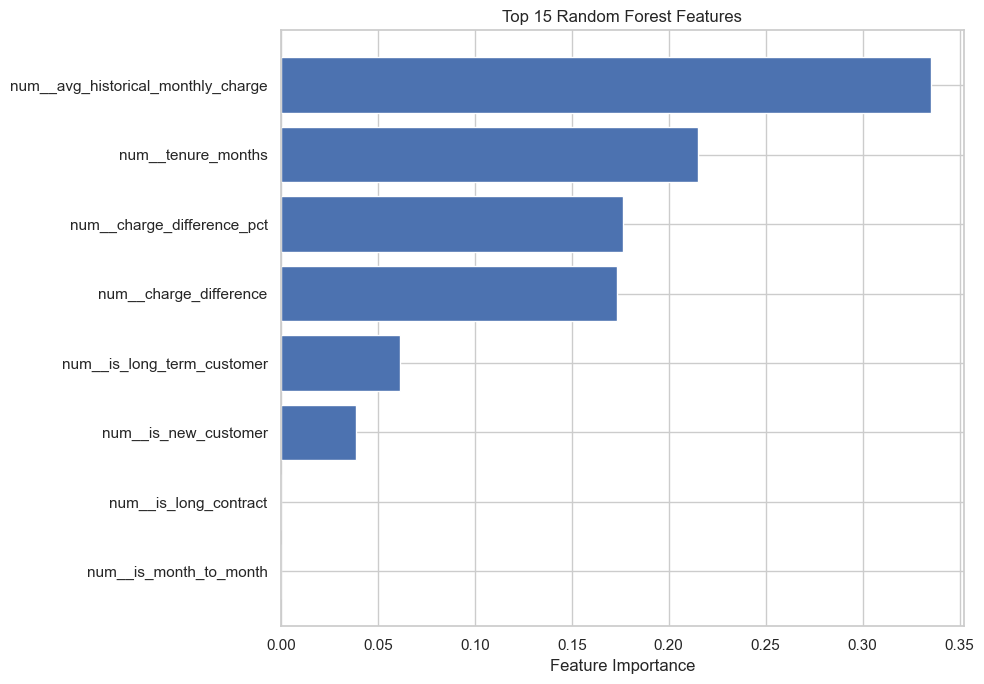

In [68]:

# Preliminary model ranking
# First, rank the models by ROC-AUC as a preliminary comparison. Then inspect Random Forest's feature importance to understand which engineered features contribute most to its predictions.

ranked_models = comparison_df.sort_values(
    by="ROC-AUC",
    ascending=False
)

print("PRELIMINARY MODEL RANKING")
display(ranked_models.round(4))

best_model_name = ranked_models.index[0]
print("Highest test ROC-AUC:", best_model_name)

# Random Forest feature importance
rf_preprocessor = rf_model.named_steps["preprocessor"]
rf_classifier = rf_model.named_steps["classifier"]

feature_names = rf_preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_classifier.feature_importances_
}).sort_values("Importance", ascending=False)

print("\nTOP 15 RANDOM FOREST FEATURES")
display(importance_df.head(15).round(4))

# Plot top 15 features
top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)
plt.xlabel("Feature Importance")
plt.title("Top 15 Random Forest Features")
plt.tight_layout()
plt.savefig(
    "random_forest_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [69]:
from pathlib import Path

# Create a folder for model-related files
output_dir = Path("../models")
output_dir.mkdir(parents=True, exist_ok=True)

# Save feature matrices
X_train.to_csv(output_dir / "X_train.csv", index=False)
X_test.to_csv(output_dir / "X_test.csv", index=False)

# Save target variables
y_train.to_csv(
    output_dir / "y_train.csv",
    index=False,
    header=["churn_target"]
)

y_test.to_csv(
    output_dir / "y_test.csv",
    index=False,
    header=["churn_target"]
)

print("Training and testing datasets saved successfully!")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)
print("Saved in:", output_dir.resolve())

Training and testing datasets saved successfully!
X_train: (5634, 8)
X_test: (1409, 8)
y_train: (5634,)
y_test: (1409,)
Saved in: C:\CHURNIQ\MODELS
